# Итоговый проект по дисциплине «Временные ряды»

Анализируем фактическое конечное потребление домашних хозяйств на душу населения по регионам России за 2000–2023 годы.

Цель: выделить похожие регионы, выбрать три примера и сравнить прогнозы Holt, ARIMA и наивной модели. Все суммы в текущих ценах: рост показателя включает инфляцию и сам по себе не означает рост реального уровня жизни.

Источник: локальный файл Росстата из задания. Прогноз на 2024–2026 годы строится из конца 2023 года, без использования более новых фактических данных.

## Этап 1. Загрузка и подготовка данных

После загрузки выполним пять пунктов: преобразуем формат таблицы, сформируем ряды, обработаем пропуски, отберём полные данные и перечислим исключённые территории.

In [217]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.arima.model import ARIMA
from sktime.forecasting.naive import NaiveForecaster

In [218]:
# Загружаем файл и проверяем размер, типы столбцов и единицы измерения.
data_path = Path('./data/rsdocs_1491005410458_wide_appendix_2025.csv')
raw = pd.read_csv(data_path)

print('Размер исходной таблицы:', raw.shape)
print('Колонки:', raw.columns.tolist())
print('Единицы:', raw['measure_unit'].iloc[0])
# .style сохраняет полные названия регионов в таблице.
display(raw[['region_name', '2000', '2023']].head().style)

raw.info()

Размер исходной таблицы: (96, 29)
Колонки: ['region_name', 'region_code', 'indicator_name', 'measure_unit', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', 'Unnamed: 28']
Единицы: в текущих рыночных ценах; рублей


,region_name,2000,2023
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,"24964,9","605276,8"
1,Центральный федеральный округ,"37398,9","745978,7"
2,Белгородская область,"19420,9",514718
3,Брянская область,"13394,1","489083,4"
4,Владимирская область,"13034,5","459450,1"


<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   region_name     96 non-null     str    
 1   region_code     94 non-null     float64
 2   indicator_name  96 non-null     str    
 3   measure_unit    96 non-null     str    
 4   2000            92 non-null     str    
 5   2001            92 non-null     str    
 6   2002            92 non-null     str    
 7   2003            92 non-null     str    
 8   2004            92 non-null     str    
 9   2005            92 non-null     str    
 10  2006            92 non-null     str    
 11  2007            92 non-null     str    
 12  2008            92 non-null     str    
 13  2009            92 non-null     str    
 14  2010            92 non-null     str    
 15  2011            94 non-null     str    
 16  2012            94 non-null     str    
 17  2013            94 non-null     str    
 18  201

Проверка структуры показала 96 записей и 29 столбцов. Годовые значения считались как текст (например, «24964,9»), а `Unnamed: 28` содержит 0 заполненных значений. Поэтому ниже убираем пустой столбец и переводим показатели в числа.

### 1. Преобразование из широкого формата в длинный

In [219]:
# Одна строка - один регион и один год, показатель - в колонке consumption (потребление)
years = [str(year) for year in range(2000, 2024)]
data = raw.dropna(axis=1, how='all').copy()
data['region_name'] = data['region_name'].str.strip()

long_data = data.melt(
    id_vars=['region_name'], value_vars=years,
    var_name='year', value_name='consumption'
)
long_data['year'] = long_data['year'].astype(int)
long_data = long_data.sort_values(['region_name', 'year']).reset_index(drop=True)

long_data.head()

,region_name,year,consumption
0,Алтайский край,2000,"15751,1"
1,Алтайский край,2001,"21539,7"
2,Алтайский край,2002,"28855,5"
3,Алтайский край,2003,"35772,7"
4,Алтайский край,2004,"44268,9"


### 2. Временной ряд для каждого региона

In [220]:
# Индекс — год, каждый столбец — ряд одной территории.
all_series = long_data.pivot(index='year', columns='region_name', values='consumption')
all_series.index = pd.PeriodIndex(all_series.index.astype(str), freq='Y')

print(all_series.shape)

all_series.iloc[:6, :4]

(24, 96)


region_name,Алтайский край,Амурская область,Архангельская область,Архангельская область без автономного округа
year,,,,
2000,"15751,1","20965,3","20638,3",NaN
2001,"21539,7","25983,5","29600,6",NaN
2002,"28855,5","33058,9",37678,NaN
2003,"35772,7","39258,2","46001,5",NaN
2004,"44268,9","50483,3","58204,3",NaN
2005,"54776,4","63172,9","73097,4",NaN


### 3. Числовой формат и пропуски

In [221]:
# Переводим значения в числа. Пустые ячейки и «…» станут NaN
for region in all_series.columns:
    all_series[region] = pd.to_numeric(
        all_series[region].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

print(all_series.shape)
print('Пропусков:', all_series.isna().sum().sum())

# для наглядности
all_series.iloc[:6, :4].round(1)

(24, 96)
Пропусков: 64


region_name,Алтайский край,Амурская область,Архангельская область,Архангельская область без автономного округа
year,,,,
2000,"15,751.100","20,965.300","20,638.300",NaN
2001,"21,539.700","25,983.500","29,600.600",NaN
2002,"28,855.500","33,058.900","37,678.000",NaN
2003,"35,772.700","39,258.200","46,001.500",NaN
2004,"44,268.900","50,483.300","58,204.300",NaN
2005,"54,776.400","63,172.900","73,097.400",NaN


### 4. Отбор территорий с полным рядом за 2000–2023 годы

In [222]:
# Оставляем полные ряды отдельных регионов
series = all_series.dropna(axis=1)
# убираем столбцы, которые содержат агрегаты вместо отдельных регионов
series = series.loc[:, ~series.columns.str.contains('всего|федеральный округ|без автономн')]

print(series.shape)
series.iloc[:6, :4].round(1)

(24, 79)


region_name,Алтайский край,Амурская область,Архангельская область,Астраханская область
year,,,,
2000,"15,751.100","20,965.300","20,638.300","17,043.600"
2001,"21,539.700","25,983.500","29,600.600","22,997.300"
2002,"28,855.500","33,058.900","37,678.000","29,804.000"
2003,"35,772.700","39,258.200","46,001.500","35,409.400"
2004,"44,268.900","50,483.300","58,204.300","43,128.700"
2005,"54,776.400","63,172.900","73,097.400","55,275.500"


### 5. Исключённые территории и причины

In [223]:
# Список территорий, которые не вошли в итоговый набор.
all_series.columns.difference(series.columns).tolist()

['Архангельская область без автономного округа',
 'Дальневосточный федеральный округ',
 'Ненецкий автономный округ',
 'Приволжский федеральный округ',
 'Республика Крым',
 'Северо-Западный федеральный округ',
 'Северо-Кавказский федеральный округ',
 'Сибирский федеральный округ',
 'Тюменская область без автономных округов',
 'Уральский федеральный округ',
 'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
 'Ханты-Мансийский автономный округ – Югра',
 'Центральный федеральный округ',
 'Чеченская Республика',
 'Южный федеральный округ',
 'Ямало-Ненецкий автономный округ',
 'г. Севастополь']

**Вывод.** Из 96 записей оставили 79 регионов с полными данными за 2000–2023 годы. В исходных годовых значениях было 64 пропуска; их не заполняли.

Исключили:

- **Неполные ряды:** Ненецкий автономный округ (3 пропуска), Ханты-Мансийский автономный округ – Югра (3), Ямало-Ненецкий автономный округ (3), Чеченская Республика (5), Республика Крым (14) и г. Севастополь (14). У этих территорий нет данных за все 24 года.
- **Дублирующие территориальные записи:** Архангельская область без автономного округа и Тюменская область без автономных округов. Они пересекаются с другими записями; кроме того, в каждом ряду отсутствуют 11 лет.
- **Все 8 федеральных округов:** Центральный федеральный округ, Северо-Западный федеральный округ, Южный федеральный округ, Северо-Кавказский федеральный округ, Приволжский федеральный округ, Уральский федеральный округ, Сибирский федеральный округ и Дальневосточный федеральный округ. Это итоги по округам, а не отдельные регионы.
- **Итог по России:** «Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего». Это общий показатель по стране.

Всего исключили 17 записей. Итоговая таблица `series` содержит 24 года и 79 регионов, пропусков нет.

## Этап 2. Кластерный анализ регионов

Используем K-means: это простой метод для числовых признаков. Признаки считаем по 2000–2017 годам, а 2018–2023 оставляем для проверки прогнозов.

### 1. Признаки для каждого региона

In [224]:
# Считаем уровень потребления и относительные изменения.
train_all = series.loc['2000':'2017']
test_all = series.loc['2018':'2023']
growth = train_all.pct_change().dropna()

cluster_features = pd.DataFrame()
cluster_features['Среднее, руб.'] = train_all.mean()
cluster_features['Коэф. вариации'] = train_all.std() / train_all.mean()
cluster_features['Средний прирост, %'] = growth.mean() * 100
cluster_features['Прирост за период, %'] = (train_all.iloc[-1] / train_all.iloc[0] - 1) * 100
cluster_features['Худший прирост, %'] = growth.min() * 100
cluster_features['Доля лет со снижением, %'] = (growth < 0).mean() * 100

cluster_features.head().round(2)

,"Среднее, руб.",Коэф. вариации,"Средний прирост, %","Прирост за период, %","Худший прирост, %","Доля лет со снижением, %"
region_name,,,,,,
Алтайский край,"115,128.310",0.660,17.890,"1,430.850",-1.030,5.880
Амурская область,"147,775.080",0.730,18.040,"1,521.100",3.510,0.000
Архангельская область,"168,225.180",0.720,19.240,"1,794.600",7.140,0.000
Астраханская область,"130,555.540",0.680,17.860,"1,435.020",1.870,0.000
Белгородская область,"132,018.310",0.750,18.210,"1,554.800",7.130,0.000


### 2. Стандартизация признаков

In [225]:
# Убираем разницу масштабов: после стандартизации значения не имеют единиц.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_features)

pd.DataFrame(scaled_features, index=cluster_features.index, columns=cluster_features.columns).head().round(3)

,"Среднее, руб.",Коэф. вариации,"Средний прирост, %","Прирост за период, %","Худший прирост, %","Доля лет со снижением, %"
region_name,,,,,,
Алтайский край,-0.600,-0.311,-0.237,-0.293,-0.487,2.486
Амурская область,0.098,1.068,-0.142,-0.047,0.153,-0.402
Архангельская область,0.535,0.820,0.603,0.696,0.666,-0.402
Астраханская область,-0.271,0.138,-0.256,-0.281,-0.078,-0.402
Белгородская область,-0.239,1.429,-0.035,0.044,0.665,-0.402


В примере для Алтайского края средний уровень после стандартизации равен −0,600, а средний прирост −0,237: оба ниже среднего по 79 регионам. Это безразмерные значения, а не рубли и проценты, несмотря на сохранённые названия признаков.

### 3. Кластеризация на 2, 3 и 4 группы

In [226]:
# Обучаем K-means для трёх вариантов числа групп.
cluster_models = {}

for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(scaled_features)
    cluster_models[k] = model

### 4. Сравнение по silhouette score

,Кластеров,Silhouette,Размеры групп
0,2,0.422,"[58, 21]"
1,3,0.381,"[11, 54, 14]"
2,4,0.397,"[54, 14, 10, 1]"


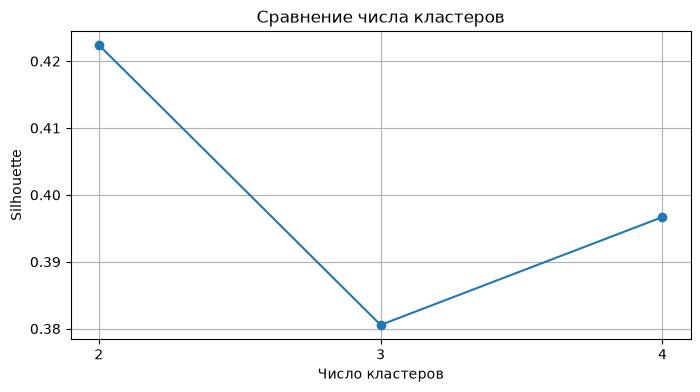

In [227]:
# Чем выше silhouette, тем лучше разделены группы.
scores = []
sizes = []

for k in [2, 3, 4]:
    labels = cluster_models[k].labels_
    scores.append(silhouette_score(scaled_features, labels))
    sizes.append(pd.Series(labels).value_counts().sort_index().tolist())

cluster_scores = pd.DataFrame({
    'Кластеров': [2, 3, 4],
    'Silhouette': scores,
    'Размеры групп': sizes
})
display(cluster_scores.round(3))

plt.figure(figsize=(8, 4))
plt.plot(cluster_scores['Кластеров'], cluster_scores['Silhouette'], marker='o')
plt.xticks([2, 3, 4])
plt.xlabel('Число кластеров')
plt.ylabel('Silhouette')
plt.title('Сравнение числа кластеров')
plt.show()

### 5. Выбор числа кластеров

In [228]:
# Выбираем три группы и добавляем их номера к регионам.
k = 3
cluster_model = cluster_models[k]
cluster_table = cluster_features.copy()
cluster_table['Кластер'] = cluster_model.labels_ + 1

Выбираем 3 группы для сравнения разных типов динамики: со снижениями и без снижений, с более быстрым и более медленным ростом (профили ниже). Это содержательный выбор: максимальный silhouette у 2 групп — 0,422, у 3 — 0,381; при 4 группах (0,397) появляется кластер всего из одного региона.

### 6. Состав и особенности групп

,"Среднее, руб.",Коэф. вариации,"Средний прирост, %","Прирост за период, %","Худший прирост, %","Доля лет со снижением, %",Регионов
Кластер,,,,,,,
1,"160,436.970",0.610,18.010,"1,318.580",-7.590,5.880,11
2,"135,251.160",0.700,18.840,"1,686.790",4.350,0.000,54
3,"160,380.320",0.610,16.270,"1,139.370",2.850,0.000,14


Кластер 1 : ['Алтайский край', 'Кемеровская область', 'Красноярский край', 'Курганская область', 'Омская область', 'Пермский край', 'Ростовская область', 'Самарская область', 'Тюменская область', 'Челябинская область', 'Чукотский автономный округ']
Кластер 2 : ['Амурская область', 'Архангельская область', 'Астраханская область', 'Белгородская область', 'Брянская область', 'Владимирская область', 'Волгоградская область', 'Воронежская область', 'Еврейская автономная область', 'Забайкальский край', 'Ивановская область', 'Кабардино-Балкарская Республика', 'Калужская область', 'Кировская область', 'Костромская область', 'Краснодарский край', 'Курская область', 'Ленинградская область', 'Липецкая область', 'Магаданская область', 'Московская область', 'Нижегородская область', 'Новгородская область', 'Оренбургская область', 'Орловская область', 'Пензенская область', 'Приморский край', 'Псковская область', 'Республика Адыгея', 'Республика Алтай', 'Республика Башкортостан', 'Республика Бурятия', 

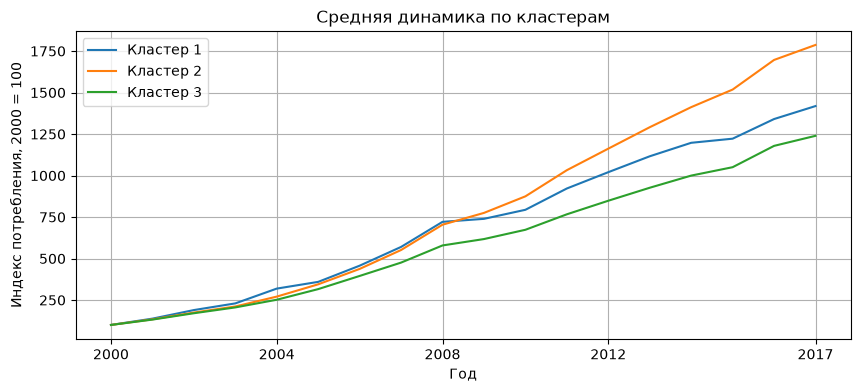

In [229]:
# Смотрим средние признаки и состав каждого кластера.
cluster_profile = cluster_table.groupby('Кластер').mean()
cluster_profile['Регионов'] = cluster_table.groupby('Кластер').size()
display(cluster_profile.round(2))

plt.figure(figsize=(10, 4))
for cluster in [1, 2, 3]:
    names = cluster_table[cluster_table['Кластер'] == cluster].index
    print('Кластер', cluster, ':', names.tolist())
    normalized = train_all[names] / train_all[names].iloc[0] * 100
    average = normalized.mean(axis=1)
    plt.plot(train_all.index.year, average, label=f'Кластер {cluster}')

plt.xlabel('Год')
plt.ylabel('Индекс потребления, 2000 = 100')
plt.title('Средняя динамика по кластерам')
plt.xticks([2000, 2004, 2008, 2012, 2017])
plt.legend()
plt.show()

### 7. Визуализация выбранных кластеров на плоскости

Используем PCA - объединяем шесть признаков в две оси, чтобы показать регионы на одном рисунке. Цвета соответствуют уже найденным кластерам; выделенные точки — регионы для дальнейшего анализа.

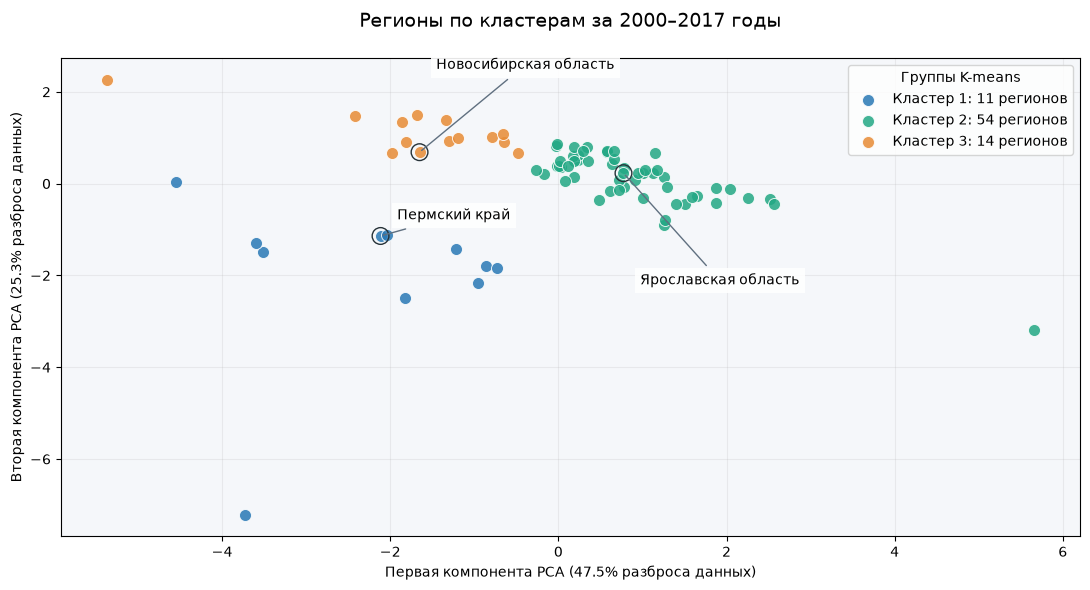

In [247]:
# Сводим шесть признаков к двум осям только для рисунка; кластеры не меняем
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
points = pd.DataFrame(
    pca.fit_transform(scaled_features),
    index=cluster_table.index, columns=['PC1', 'PC2']
)
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(11, 6))
plt.gca().set_facecolor('#f5f7fa')
for cluster, color in [(1, '#2878b5'), (2, '#22a884'), (3, '#e78b35')]:
    group = points[cluster_table['Кластер'] == cluster]
    plt.scatter(group['PC1'], group['PC2'], s=75, color=color,
                edgecolors='white', linewidths=0.7, alpha=0.85,
                label=f'Кластер {cluster}: {len(group)} регионов', zorder=2)

# Подписываем три региона, которые будем сравнивать дальше
for region, offset in [('Пермский край', (12, 12)),
                       ('Ярославская область', (12, -80)),
                       ('Новосибирская область', (12, 60))]:
    x, y = points.loc[region]
    plt.scatter(x, y, s=145, facecolors='none', edgecolors='#263238', zorder=3)
    plt.annotate(region, (x, y), xytext=offset, textcoords='offset points',
                 fontsize=10, bbox=dict(facecolor='white', edgecolor='none', alpha=0.9),
                 arrowprops=dict(arrowstyle='-', color='#607080'), zorder=4)

plt.xlabel(f'Первая компонента PCA ({variance[0]:.1f}% разброса данных)')
plt.ylabel(f'Вторая компонента PCA ({variance[1]:.1f}% разброса данных)')
plt.title('Регионы по кластерам за 2000–2017 годы\n', fontsize=14)
plt.legend(title='Группы K-means', loc='upper right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**По графику.** Показаны 79 регионов: 11 в кластере 1, 54 в кластере 2 и 14 в кластере 3. Две оси сохраняют 72,8% общего разброса признаков. Точки разных групп могут пересекаться на рисунке: кластеризация учитывает все шесть признаков, а здесь показаны только две компоненты.

**Вывод.** По таблице профилей и графику средней динамики за 2000–2017 годы:

- **Кластер 1:** 11 регионов, среднее потребление 160,4 тыс. руб., средний прирост 18,0% в год; доля лет со снижением 5,88%.
- **Кластер 2:** 54 региона, 135,3 тыс. руб. и 18,8%; снижений нет. На графике он вырос сильнее остальных: индекс к 2017 году - 1786,8 при базе 100.
- **Кластер 3:** 14 регионов, 160,4 тыс. руб. и 16,3%; снижений нет. Итоговый индекс 1239,4 ниже, чем у кластера 1 (1418,6) и кластера 2.

## Этап 3. Выбор регионов

### 1. Выбор трёх регионов

In [231]:
# Берём по одному представителю каждого кластера.
selected_regions = ['Пермский край', 'Ярославская область', 'Новосибирская область']
selection = cluster_table.loc[selected_regions, ['Кластер', 'Среднее, руб.', 'Средний прирост, %', 'Худший прирост, %']]

selection.round(2)

,Кластер,"Среднее, руб.","Средний прирост, %","Худший прирост, %"
region_name,,,,
Пермский край,1,"161,351.070",17.150,-1.480
Ярославская область,2,"131,312.520",18.650,4.440
Новосибирская область,3,"158,415.860",16.830,0.310


### 2. Обоснование выбора

Сравниваем таблицу выбранных регионов с профилями кластеров за 2000–2017 годы:

- **Пермский край:** средний уровень 161,4 тыс. руб. близок к 160,4 тыс. в кластере 1; худший годовой прирост −1,48% подтверждает наличие снижения.
- **Ярославская область:** средний прирост 18,65% близок к 18,84% в кластере 2; даже минимальный прирост положителен (+4,44%).
- **Новосибирская область:** средний уровень 158,4 тыс. руб. против 160,4 тыс. в кластере 3; прирост 16,83% против 16,27%. Здесь рост медленнее, чем в Ярославской области.

### 3. Основные статистики

In [232]:
# Считаем статистики за весь период.
region_stats = pd.DataFrame()
region_stats['Среднее, руб.'] = series[selected_regions].mean()
region_stats['Минимум, руб.'] = series[selected_regions].min()
region_stats['Максимум, руб.'] = series[selected_regions].max()
region_stats['СКО приростов, п.п.'] = series[selected_regions].pct_change().std() * 100

for region in selected_regions:
    region_stats.loc[region, 'Тренд, руб./год'] = np.polyfit(np.arange(len(series)), series[region], 1)[0]

region_stats.round(2)

,"Среднее, руб.","Минимум, руб.","Максимум, руб.","СКО приростов, п.п.","Тренд, руб./год"
region_name,,,,,
Пермский край,"221,578.490","23,115.300","489,939.100",10.480,"19,833.370"
Ярославская область,"199,438.090","17,415.200","515,267.800",10.040,"20,610.520"
Новосибирская область,"220,986.210","23,071.500","574,377.800",11.290,"19,982.660"


**Вывод.** По таблице статистик среднее потребление за 2000–2023 годы составляет 221,6 тыс. руб. в Пермском крае, 199,4 тыс. в Ярославской области и 221,0 тыс. в Новосибирской.<br>Диапазоны значений: 23,1–489,9; 17,4–515,3 и 23,1–574,4 тыс. руб. соответственно.<br>
У Новосибирской области самый высокий максимум!

## Этап 4. Анализ рядов

ADF, ACF и PACF считаем по обучающему периоду 2000–2017 годов.

### 1. Графики потребления

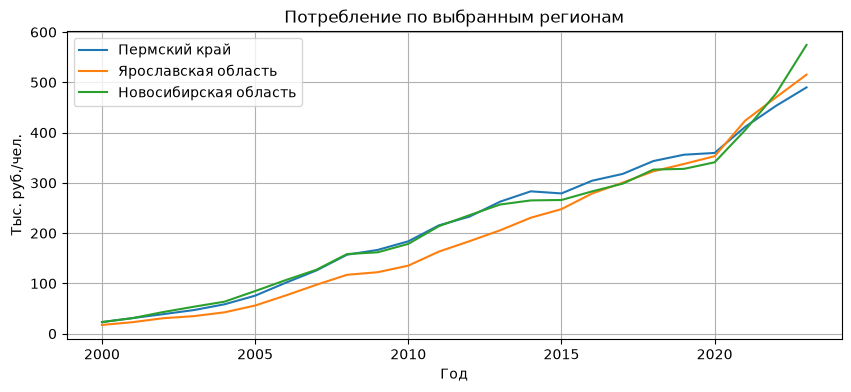

In [233]:
# Сравниваем исходные ряды.
plt.figure(figsize=(10, 4))
for region in selected_regions:
    plt.plot(series.index.year, series[region] / 1000, label=region)

plt.xlabel('Год')
plt.ylabel('Тыс. руб./чел.')
plt.title('Потребление по выбранным регионам')
plt.legend()
plt.show()

На графике к 2023 году Новосибирская область достигла 574,4 тыс. руб. на человека, Ярославская - 515,3 тыс., Пермский край - 489,9 тыс. От 2020 к 2023 году показатель вырос соответственно с 340,9; 353,0; 359,5 тыс.: самый сильный подъём виден у Новосибирской области!

### 2. Выделение тренда

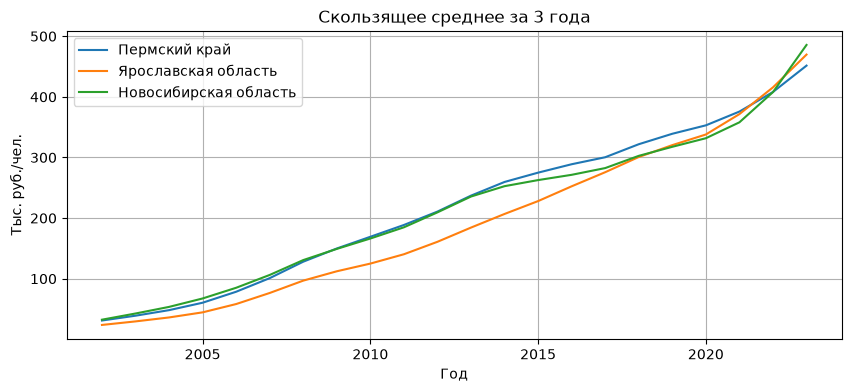

In [234]:
# Сглаживаем колебания средним за три года
trend = series[selected_regions].rolling(3).mean()

plt.figure(figsize=(10, 4))
for region in selected_regions:
    plt.plot(trend.index.year, trend[region] / 1000, label=region)

plt.xlabel('Год')
plt.ylabel('Тыс. руб./чел.')
plt.title('Скользящее среднее за 3 года')
plt.legend()
plt.show()

График трёхлетнего среднего подтверждает общий рост: с 2017 до 2023 года сглаженный уровень вырос с 300,4 до 451,5 тыс. руб. в Пермском крае, с 275,7 до 469,7 тыс. в Ярославской области и с 282,5 до 485,6 тыс. в Новосибирской. Усреднение уменьшает влияние отдельных лет, но сохраняет подъём.

### 3. Тест Дики - Фуллера

In [235]:
#  При p-value < 0.05 отвергаем гипотезу о единичном корне
adf_rows = []

for region in selected_regions:
    y = train_all[region] / 1000
    p_level = adfuller(y, maxlag=3, autolag='AIC', result_object=False)[1]
    p_diff = adfuller(y.diff().dropna(), maxlag=3, autolag='AIC', result_object=False)[1]
    adf_rows.append([region, p_level, p_diff])

adf_results = pd.DataFrame(adf_rows, columns=['Регион', 'p-value уровня', 'p-value разности'])

adf_results

,Регион,p-value уровня,p-value разности
0,Пермский край,0.985,0.035
1,Ярославская область,1.000,0.154
2,Новосибирская область,0.959,0.014


В таблице ADF для уровней p-value = 0,985; 1,000; 0,959: при пороге 0,05 гипотезу о единичном корне не отвергаем. После первой разности у Пермского края и Новосибирской области p-value = 0,035 и 0,014, у Ярославской - 0,154; для неё стоит проверить вторую разность. Всего 18 обучающих точек, поэтому не считаем результат теста окончательным доказательством.

### 4. ACF, PACF и предположения о порядках ARIMA

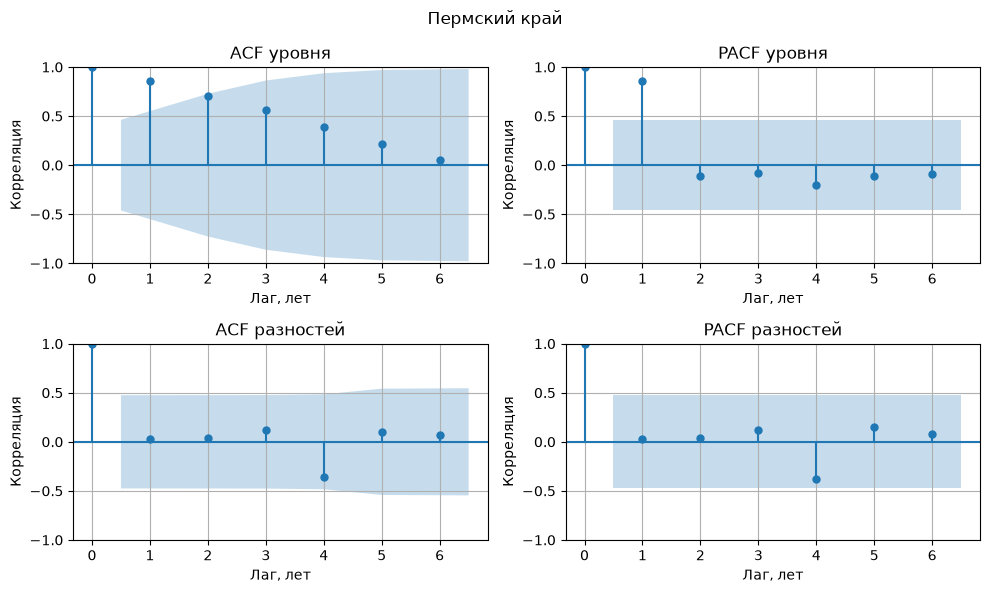

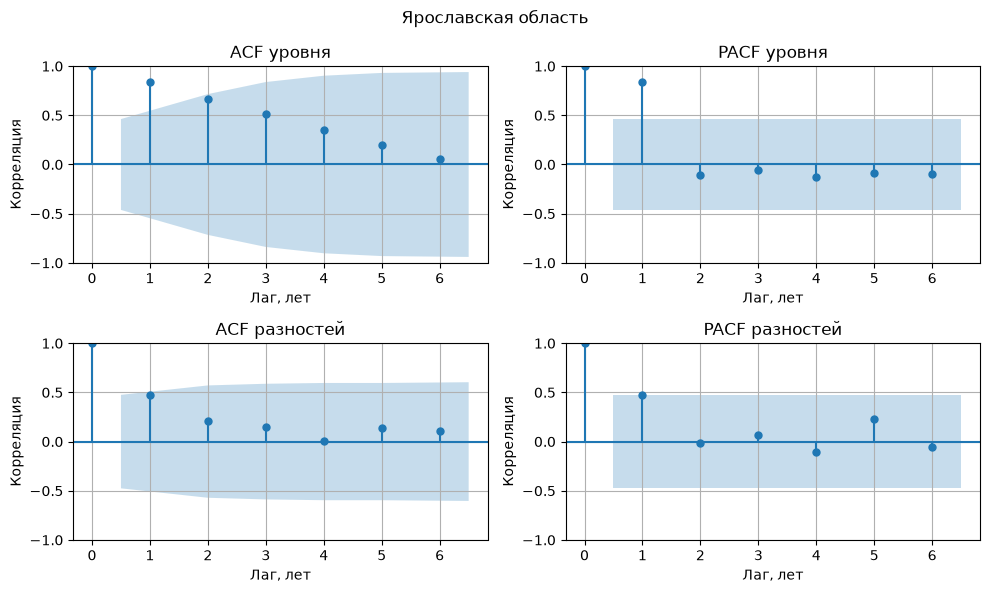

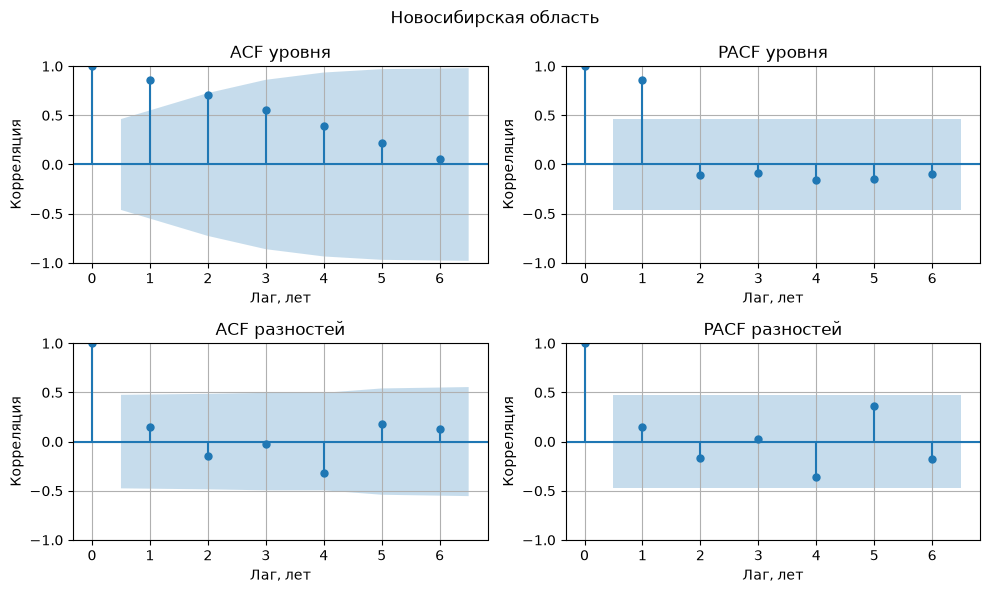

In [236]:
# Смотрим корреляции уровней и первых разностей
for region in selected_regions:
    y = train_all[region] / 1000
    diff = y.diff().dropna()
    fig, axes = plt.subplots(2, 2, figsize=(10, 6))
    plot_acf(y, lags=6, ax=axes[0, 0], title='ACF уровня')
    plot_pacf(y, lags=6, method='ywm', ax=axes[0, 1], title='PACF уровня')
    plot_acf(diff, lags=6, ax=axes[1, 0], title='ACF разностей')
    plot_pacf(diff, lags=6, method='ywm', ax=axes[1, 1], title='PACF разностей')
    fig.suptitle(region)

    # оси
    for ax in axes.flat:
        ax.set_xlabel('Лаг, лет')
        ax.set_ylabel('Корреляция')
    plt.tight_layout()
    plt.show()

На графиках ACF уровней корреляция на лаге 1 высокая: 0,86; 0,84; 0,86 для Пермского края, Ярославской и Новосибирской областей. После разностей она равна 0,03; 0,47; 0,15; на PACF разностей у Ярославской области также заметнее всего лаг 1 (0,47). Поэтому начальные кандидаты - небольшие p и q (0 или 1); эти графики сами по себе не определяют лучший порядок ARIMA.

### 5. Сравнение регионов и сезонность

**Вывод.** По статистикам этапа 3 наклон тренда равен 19,8; 20,6; 20,0 тыс. руб./год для Пермского края, Ярославской и Новосибирской областей. Самый высокий разброс годовых приростов у Новосибирской области: 11,29 п.п. против 10,48 и 10,04. В году есть только одно наблюдение, поэтому внутригодовую сезонность оценить нельзя; по 24 точкам и графикам ACF/PACF не делаем вывод о стабильном многолетнем цикле.

## Этап 5. Прогнозирование

Сравниваем Holt, ARIMA и наивный прогноз. Модели выбираем по валидации внутри train, test соответственно используем только для оценки. Обучаем в тысячах рублей, прогнозы и ошибки возвращаем в рубли.

### 1. Разбиение данных и горизонт прогноза

In [237]:
# Первые 18 лет - обучение, последние 6 будет test
train = series[selected_regions].loc['2000':'2017']
test = series[selected_regions].loc['2018':'2023']
inner_train = train.loc['2000':'2013']
validation = train.loc['2014':'2017']

horizon = 3
future_index = pd.period_range('2024', periods=horizon, freq='Y')

print('Train:', train.shape, 'Test:', test.shape)
print('Доля обучения:', len(train) / len(series))

Train: (18, 3) Test: (6, 3)
Доля обучения: 0.75


### 2. Прогноз Holt

In [238]:
# Отдельно считаем прогнозы для валидации, теста и будущих лет
holt_validation = pd.DataFrame(index=validation.index)
holt_test = pd.DataFrame(index=test.index)
holt_future = pd.DataFrame(index=future_index)

for region in selected_regions:
    # Валидация нужна для выбора модели без использования теста.
    model = Holt(inner_train[region] / 1000, initialization_method='estimated').fit()
    holt_validation[region] = model.forecast(len(validation)) * 1000

    # Тест оценивает прогноз из конца 2017 года сразу на 6 лет
    model = Holt(train[region] / 1000, initialization_method='estimated').fit()
    holt_test[region] = model.forecast(len(test)) * 1000

    # Для 2024-2026 годов переобучаем модель на всех доступных данных
    model = Holt(series[region] / 1000, initialization_method='estimated').fit()
    holt_future[region] = model.forecast(horizon) * 1000

holt_test

,Пермский край,Ярославская область,Новосибирская область
year,,,
2018,"335,192.738","323,888.882","314,684.840"
2019,"352,530.375","347,318.064","330,885.580"
2020,"369,868.013","370,747.245","347,086.320"
2021,"387,205.651","394,176.427","363,287.060"
2022,"404,543.289","417,605.609","379,487.800"
2023,"421,880.926","441,034.791","395,688.540"


В таблице Holt прогноз на 2018–2023 годы растёт: с 335,2 до 421,9 тыс. руб. в Пермском крае, с 323,9 до 441,0 тыс. в Ярославской области и с 314,7 до 395,7 тыс. в Новосибирской.<br>Модель продолжает линейный тренд.

### 3. Прогноз ARIMA

In [239]:
# Фиксируем небольшие порядки ARIMA для сравнения с другими моделями.
arima_orders = {
    'Пермский край': (0, 2, 1),
    'Ярославская область': (0, 2, 0),
    'Новосибирская область': (0, 2, 1)
}
arima_validation = pd.DataFrame(index=validation.index)
arima_test = pd.DataFrame(index=test.index)
arima_future = pd.DataFrame(index=future_index)

for region in selected_regions:
    # Валидация  нужна для выбора модели без использования теста
    order = arima_orders[region]
    model = ARIMA(inner_train[region] / 1000, order=order).fit()
    arima_validation[region] = model.forecast(len(validation)) * 1000

    # Тест оценивает прогноз из конца 2017 года сразу на 6 лет
    model = ARIMA(train[region] / 1000, order=order).fit()
    arima_test[region] = model.forecast(len(test)) * 1000

    # для 2024–2026 годов переобучаем модель на всех доступных данных
    model = ARIMA(series[region] / 1000, order=order).fit()
    arima_future[region] = model.forecast(horizon) * 1000

arima_test

,Пермский край,Ярославская область,Новосибирская область
year,,,
2018,"335,016.674","322,077.700","314,684.772"
2019,"352,178.247","343,695.700","330,885.443"
2020,"369,339.821","365,313.700","347,086.115"
2021,"386,501.394","386,931.700","363,286.786"
2022,"403,662.968","408,549.700","379,487.458"
2023,"420,824.541","430,167.700","395,688.129"


Здесь фиксируем ARIMA(0, 2, 1) для Пермского края и Новосибирской области, ARIMA(0, 2, 0) - для Ярославской. По тесту ADF для Пермского края и Новосибирской области после одной разности тест ADF уже указывает на стационарность ряда: p-value равны 0,035 и 0,014 - меньше 0,05. Поэтому использование двух разностей (d = 2) здесь требует дополнительной проверки. На тесте к 2023 году прогнозы ARIMA и Holt близки в Пермском крае (420,8 и 421,9 тыс. руб.) и Новосибирской области (оба около 395,7 тыс.), в Ярославской ARIMA ниже — 430,2 против 441,0 тыс.

### 4. Наивный прогноз

In [240]:
# Наивная модель повторяет последнее известное значение.
naive_validation = pd.DataFrame(index=validation.index)
naive_test = pd.DataFrame(index=test.index)
naive_future = pd.DataFrame(index=future_index)

for region in selected_regions:
    model = NaiveForecaster(strategy='last')
    # Валидация до тестового периода.
    model.fit(inner_train[region] / 1000)
    naive_validation[region] = model.predict(fh=np.arange(1, len(validation) + 1)) * 1000

    model = NaiveForecaster(strategy='last')
    # Прогноз на тест без обновления по его фактическим значениям.
    model.fit(train[region] / 1000)
    naive_test[region] = model.predict(fh=np.arange(1, len(test) + 1)) * 1000

    model = NaiveForecaster(strategy='last')
    # Прогноз будущего после обучения на данных до 2023 года.
    model.fit(series[region] / 1000)
    naive_future[region] = model.predict(fh=np.arange(1, horizon + 1)) * 1000

naive_test

,Пермский край,Ярославская область,Новосибирская область
year,,,
2018,"317,855.100","300,459.700","298,484.100"
2019,"317,855.100","300,459.700","298,484.100"
2020,"317,855.100","300,459.700","298,484.100"
2021,"317,855.100","300,459.700","298,484.100"
2022,"317,855.100","300,459.700","298,484.100"
2023,"317,855.100","300,459.700","298,484.100"


Таблица Naive повторяет уровень 2017 года: 317,9; 300,5; 298,5 тыс. руб. для Пермского края, Ярославской и Новосибирской областей. Такая горизонтальная линия не отражает рост факта к 2023 году до 489,9; 515,3; 574,4 тыс. руб.

### 5. Метрики RMSE и MAPE

In [241]:
# Сравниваем все модели на одинаковых периодах
model_predictions = {'Holt': holt_test, 'ARIMA': arima_test, 'Naive': naive_test}
validation_predictions = {'Holt': holt_validation, 'ARIMA': arima_validation, 'Naive': naive_validation}
future_predictions = {'Holt': holt_future, 'ARIMA': arima_future, 'Naive': naive_future}
metric_rows = []

for name in model_predictions:
    for region in selected_regions:
        prediction = model_predictions[name][region]
        val_prediction = validation_predictions[name][region]
        rmse = mean_squared_error(test[region], prediction) ** 0.5
        mape = mean_absolute_percentage_error(test[region], prediction) * 100
        val_rmse = mean_squared_error(validation[region], val_prediction) ** 0.5
        metric_rows.append([region, name, rmse, mape, val_rmse])

test_metrics = pd.DataFrame(metric_rows, columns=[
    'Регион', 'Модель', 'RMSE, руб.', 'MAPE, %', 'RMSE валидации, руб.'
])

test_metrics

,Регион,Модель,"RMSE, руб.","MAPE, %","RMSE валидации, руб."
0,Пермский край,Holt,"35,975.463",6.129,"15,476.021"
1,Ярославская область,Holt,"39,885.249",6.785,"7,171.137"
2,Новосибирская область,Holt,"85,102.406",11.380,"25,168.026"
3,Пермский край,ARIMA,"36,574.554",6.227,"32,842.204"
4,Ярославская область,ARIMA,"45,772.748",7.312,"5,991.355"
5,Новосибирская область,ARIMA,"85,102.636",11.380,"34,681.308"
6,Пермский край,Naive,"100,434.012",19.583,"36,944.549"
7,Ярославская область,Naive,"125,683.438",23.296,"64,660.141"
8,Новосибирская область,Naive,"143,150.776",23.637,"25,246.931"


По таблице тестовый RMSE Holt ниже Naive во всех регионах: 36,0 против 100,4 тыс. руб. в Пермском крае, 39,9 против 125,7 тыс. в Ярославской области и 85,1 против 143,2 тыс. в Новосибирской.<br>MAPE Holt - 6,13%; 6,79%; 11,38%, поэтому Новосибирская область труднее для прогноза и в относительных единицах. Здесь Holt и ARIMA отличаются по RMSE лишь на 0,23 рубля - практически одинаковый результат на этом тесте.

### 6. Выбор моделей и проверка rolling window

In [242]:
# Выбираем модель по валидации - затем проверяем обновление каждый год
best_models = {}
for region in selected_regions:
    rows = test_metrics[test_metrics['Регион'] == region]
    best_row = rows['RMSE валидации, руб.'].idxmin()
    best_models[region] = rows.loc[best_row, 'Модель']

# Функция делает один прогноз, чтобы не повторять условия внутри циклов
def next_year(y, name, order):
    if name == 'Holt':
        model = Holt(y, initialization_method='estimated').fit()
        return model.forecast(1).iloc[0]
    if name == 'ARIMA':
        model = ARIMA(y, order=order).fit()
        return model.forecast(1).iloc[0]
    return y.iloc[-1]

# Окно содержит только 18 прошлых лет, прогнозируем один следующий год
rolling_predictions = pd.DataFrame(index=test.index, columns=selected_regions, dtype=float)
for region in selected_regions:
    for position in range(len(train), len(series)):
        window = series[region].iloc[position - len(train):position] / 1000
        prediction = next_year(window, best_models[region], arima_orders[region])
        rolling_predictions.loc[series.index[position], region] = prediction * 1000

# Сравниваем ошибки двух способов прогнозирования на 2018–2023 годах
stability_rows = []
for region in selected_regions:
    name = best_models[region]
    fixed = model_predictions[name][region]
    rolling = rolling_predictions[region]
    fixed_rmse = mean_squared_error(test[region], fixed) ** 0.5
    rolling_rmse = mean_squared_error(test[region], rolling) ** 0.5
    fixed_mape = mean_absolute_percentage_error(test[region], fixed) * 100
    rolling_mape = mean_absolute_percentage_error(test[region], rolling) * 100
    improvement = (1 - rolling_rmse / fixed_rmse) * 100
    stability_rows.append([region, name, fixed_rmse, rolling_rmse, fixed_mape, rolling_mape, improvement])

stability = pd.DataFrame(stability_rows, columns=[
    'Регион', 'Модель', 'Fixed RMSE, руб.', 'Rolling RMSE, руб.',
    'Fixed MAPE, %', 'Rolling MAPE, %', 'Снижение RMSE, %'
])

stability

,Регион,Модель,"Fixed RMSE, руб.","Rolling RMSE, руб.","Fixed MAPE, %","Rolling MAPE, %","Снижение RMSE, %"
0,Пермский край,Holt,"35,975.463","21,098.391",6.129,4.440,41.353
1,Ярославская область,ARIMA,"45,772.748","25,043.614",7.312,3.565,45.287
2,Новосибирская область,Holt,"85,102.406","39,868.802",11.380,7.115,53.152


По RMSE валидации выбраны:
- Пермский край - Holt (15,5 тыс. руб. против 32,8 у ARIMA и 36,9 у Naive)
- Ярославская область - ARIMA (6,0 против 7,2 и 64,7)
- Новосибирская область - Holt (25,17 против 34,68 и 25,25)

В таблице rolling RMSE снизился с 36,0 до 21,1 тыс. руб. в Пермском крае, с 45,8 до 25,0 в Ярославской области и с 85,1 до 39,9 в Новосибирской. Это другая задача: окно 18 лет, горизонт 1 год и ежегодное обновление вместо фиксированного прогноза на 6 лет.

### 7. Графики прогнозов на тест и будущие годы

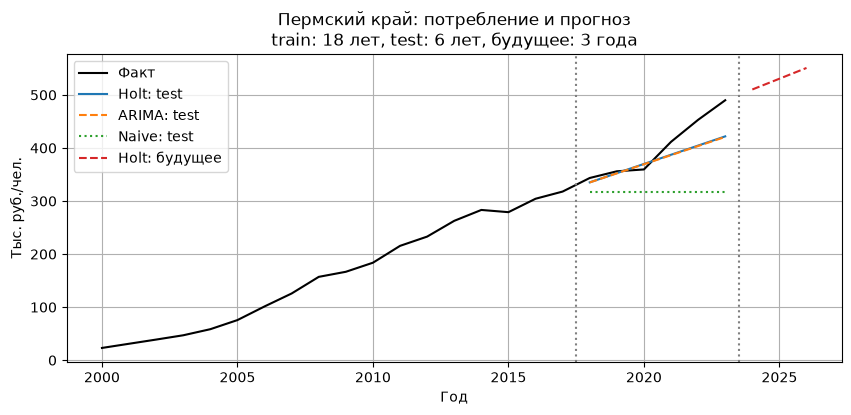

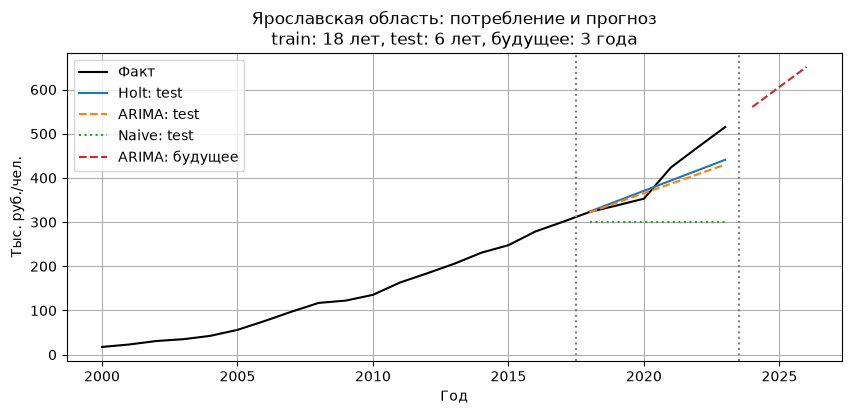

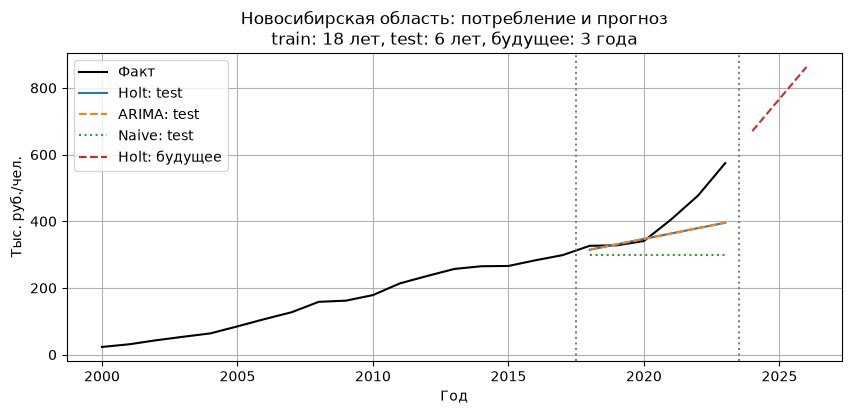

In [243]:
# Сохраняем будущие значения и показываем прогнозы выбранных моделей
future_rows = []
for region in selected_regions:
    name = best_models[region]
    prediction = future_predictions[name][region]
    last = series[region].iloc[-1]
    growth = (prediction.iloc[-1] / last - 1) * 100
    future_rows.append([region, name, last, prediction.iloc[0], prediction.iloc[1], prediction.iloc[2], growth])

future_summary = pd.DataFrame(future_rows, columns=[
    'Регион', 'Модель', 'Факт 2023, руб.', 'Прогноз 2024, руб.',
    'Прогноз 2025, руб.', 'Прогноз 2026, руб.', 'Прирост 2026 к 2023, %'
])

for region in selected_regions:
    name = best_models[region]
    plt.figure(figsize=(10, 4))
    plt.plot(series.index.year, series[region] / 1000, color='black', label='Факт')
    plt.plot(test.index.year, holt_test[region] / 1000, label='Holt: test')
    plt.plot(test.index.year, arima_test[region] / 1000, linestyle='--', label='ARIMA: test')
    plt.plot(test.index.year, naive_test[region] / 1000, linestyle=':', label='Naive: test')
    plt.plot(future_index.year, future_predictions[name][region] / 1000, '--', label=f'{name}: будущее')
    plt.axvline(2017.5, color='gray', linestyle=':')
    plt.axvline(2023.5, color='gray', linestyle=':')
    plt.xlabel('Год')
    plt.ylabel('Тыс. руб./чел.')
    plt.title(f'{region}: потребление и прогноз\ntrain: 18 лет, test: 6 лет, будущее: 3 года')
    plt.legend()
    plt.show()

**Вывод по графикам.** К концу теста выбранные модели недооценивают потребление:

- **Пермский край:** Holt даёт 421,9 тыс. руб. за 2023 год при факте 489,9; прогноз на 2026 год после переобучения - 550,8 тыс.
- **Ярославская область:** ARIMA даёт 430,2 тыс. при факте 515,3; прогноз на 2026 год - 651,2 тыс. На тесте Holt точнее (RMSE 39,9 против 45,8 тыс.), но выбор по валидации не меняем задним числом.
- **Новосибирская область:** Holt даёт 395,7 тыс. при факте 574,4; после переобучения прогноз на 2026 год - 863,0 тыс. Резкое изменение наклона показывает чувствительность прогноза к последним годам.

Будущий прогноз обучен заново на 2000–2023 годах, поэтому он не является продолжением линии прогноза из конца 2017 года.

## Этап 6. Анализ ошибок

### 1. Пять крупнейших ошибок

In [244]:
# Находим годы с наибольшей абсолютной ошибкой выбранных моделей.
errors = pd.DataFrame(index=test.index)
top_errors = {}

for region in selected_regions:
    name = best_models[region]
    errors[region] = test[region] - model_predictions[name][region]
    top_errors[region] = errors[region].abs().nlargest(5).index

### 2. Таблицы и график ошибок

Пермский край


,"Факт, руб.","Прогноз, руб.","Ошибка, руб.","Ошибка, %"
year,,,,
2023,"489,939.100","421,880.930","68,058.170",13.890
2022,"453,055.200","404,543.290","48,511.910",10.710
2021,"411,557.600","387,205.650","24,351.950",5.920
2020,"359,534.400","369,868.010","-10,333.610",-2.870
2018,"343,435.700","335,192.740","8,242.960",2.400


Ярославская область


,"Факт, руб.","Прогноз, руб.","Ошибка, руб.","Ошибка, %"
year,,,,
2023,"515,267.800","430,167.700","85,100.100",16.520
2022,"469,959.500","408,549.700","61,409.800",13.070
2021,"423,941.300","386,931.700","37,009.600",8.730
2020,"353,048.100","365,313.700","-12,265.600",-3.470
2019,"337,644.400","343,695.700","-6,051.300",-1.790


Новосибирская область


,"Факт, руб.","Прогноз, руб.","Ошибка, руб.","Ошибка, %"
year,,,,
2023,"574,377.800","395,688.540","178,689.260",31.110
2022,"477,403.700","379,487.800","97,915.900",20.510
2021,"405,139.500","363,287.060","41,852.440",10.330
2018,"326,455.500","314,684.840","11,770.660",3.610
2020,"340,927.500","347,086.320","-6,158.820",-1.810


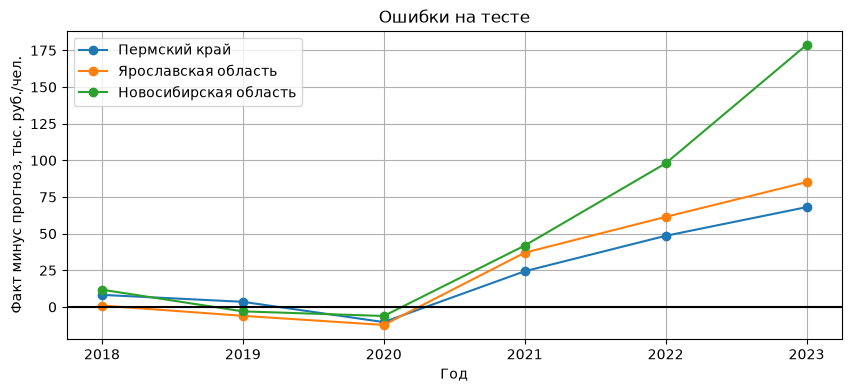

In [245]:
# Положительная ошибка означает, что прогноз был занижен
for region in selected_regions:
    error_years = top_errors[region]
    name = best_models[region]
    table = pd.DataFrame(index=error_years)
    table['Факт, руб.'] = test.loc[error_years, region]
    table['Прогноз, руб.'] = model_predictions[name].loc[error_years, region]
    table['Ошибка, руб.'] = errors.loc[error_years, region]
    table['Ошибка, %'] = table['Ошибка, руб.'] / table['Факт, руб.'] * 100
    print(region)
    display(table.round(2))

plt.figure(figsize=(10, 4))
for region in selected_regions:
    plt.plot(errors.index.year, errors[region] / 1000, marker='o', label=region)

plt.axhline(0, color='black')
plt.xlabel('Год')
plt.ylabel('Факт минус прогноз, тыс. руб./чел.')
plt.title('Ошибки на тесте')
plt.legend()
plt.show()

### 3. Предположения о причинах ошибок

**Вывод.**<br>Во всех трёх таблицах первые места по абсолютной ошибке занимают 2023, 2022 и 2021 годы. В 2023 году недооценка составила 68,1 тыс. руб. (13,89%) в Пермском крае, 85,1 тыс. (16,52%) в Ярославской области и 178,7 тыс. (31,11%) в Новосибирской; график ошибок показывает наибольшее расхождение именно у Новосибирской области.

В 2020 году знак ошибки обратный: −10,3; −12,3; −6,2 тыс. руб. соответственно. Замедление относительно прогноза могло быть связано с пандемией, а рост ошибок в 2021 году - с восстановлением спроса.

В 2022 году недооценка выросла до 48,5; 61,4; 97,9 тыс. руб.; возможное объяснение это сильный рост инфляции в это год.

## Этап 7. Индивидуальные рекомендации

Рекомендации относятся к сценарию на 2024–2026 годы, построенному по данным до конца 2023 года.

### 1. Рекомендации каждому региону

**Пермский край**

- Для сценарного плана потребления Пермского края заложить постепенный прирост около 20,3 тыс. руб. на человека ежегодно. Годовые ориентиры Holt составляют 510,2 → 530,5 → 550,8 тыс. руб. в 2024–2026 годах. Это прибавка 60,9 тыс. руб. (+12,4%) к уровню 2023 года - самый умеренный рост среди трёх регионов.
- Перед использованием ориентира 550,8 тыс. руб. проверить, покрывает ли прирост +12,4% накопленное повышение цен за 2024–2026 годы. Если рост цен по региональному дефлятору потребления превысит примерно 12,4%, этот сценарий будет соответствовать снижению реального потребления. Тогда пересмотреть план реальных объёмов с учётом дефлятора.

**Ярославская область**

- В среднесрочном плане Ярославской области предусмотреть поэтапный рост потребления до 560,6 тыс. руб. в 2024 году, 605,9 тыс. в 2025 году и 651,2 тыс. в 2026 году. Использовать прибавку около 45,3 тыс. руб. ежегодно. За три года она составит 135,9 тыс. руб. (+26,4%) к уровню 2023 года.
- Перед принятием 651,2 тыс. руб. как основного ориентира на 2026 год повторно сравнить ARIMA и Holt на обновлённой валидации и пересчитать этот ориентир выбранной моделью. Для Ярославской области такая проверка особенно нужна так как ARIMA выиграла прежнюю валидацию с RMSE 6,0 против 7,2 тыс. руб., но уступила Holt на тесте с RMSE 45,8 против 39,9 тыс. руб.

**Новосибирская область**

- Для Новосибирской области рассматривать 863,0 тыс. руб. на человека к 2026 году как сценарий сохранения быстрого роста. При планировании прирост 288,6 тыс. руб. (+50,2% к 2023 году) распределить на три годовых этапа примерно по 96,2 тыс. руб. И это самый высокий темп среди выбранных регионов.
- Решения, основанные на ориентирах 766,8 тыс. руб. в 2025 году и 863,0 тыс. в 2026 году, принимать после сопоставления факта 2024 года с прогнозом 670,6 тыс. руб. и пересчёта модели на новых данных. Для Новосибирской области такой контроль особенно важен - MAPE выбранной модели на тесте составляет 11,38%, а недооценка 2023 года достигла 31,11%.

### 2. Числа для обоснования рекомендаций

In [246]:
# Выводим прогнозные значения, на которых основаны рекомендации.
future_summary.round(2)

,Регион,Модель,"Факт 2023, руб.","Прогноз 2024, руб.","Прогноз 2025, руб.","Прогноз 2026, руб.","Прирост 2026 к 2023, %"
0,Пермский край,Holt,"489,939.100","510,235.780","530,532.470","550,829.150",12.430
1,Ярославская область,ARIMA,"515,267.800","560,576.100","605,884.400","651,192.700",26.380
2,Новосибирская область,Holt,"574,377.800","670,574.510","766,771.220","862,967.920",50.240


**Вывод.**<br>Для Пермского края предложен умеренный сценарий +12,4% с проверкой влияния цен.<br>Для Ярославской области поэтапный рост +26,4% и проверка модели перед использованием ориентира 651,2 тыс. руб.<br>Для Новосибирской области базовый сценарий +50,2% с проверкой ближайшего годового прогноза 670,6 тыс. руб. перед дальнейшим планированием.

## Этап 8. Выводы по проекту

**Лучшей моделью на тестовом периоде 2018–2023 годов оказалась Holt. Она получила минимальный RMSE у представителей всех трёх групп регионов.** Для Новосибирской области результаты Holt и ARIMA практически совпали.

### 1. Какие группы регионов выделились

По данным 79 регионов за 2000–2017 годы выделены три группы (этап 2).

- **Группа 1** включает 11 регионов с отдельными годами снижения потребления. Средний годовой прирост составляет 18,0%, средний уровень — 160,4 тыс. руб. на человека. Представителем выбран Пермский край.
- **Группа 2** включает 54 региона с непрерывным и наиболее быстрым ростом. Средний прирост составляет 18,8%, средний уровень — 135,3 тыс. руб. Представитель — Ярославская область.
- **Группа 3** включает 14 регионов с более медленным непрерывным ростом. Средний прирост составляет 16,3%, средний уровень — 160,4 тыс. руб. Представитель — Новосибирская область.

### 2. Какая модель наиболее эффективна

В каждой группе модели проверены на одном выбранном ранее регионе. По метрикам этапа 5 получено следующее сравнение. RMSE указан в тысячах рублей на человека.

| Группа и представитель | RMSE Holt | RMSE ARIMA | RMSE Наивный | MAPE Holt, % |
| --- | ---: | ---: |-------------:| ---: |
| 1 — Пермский край | **35,98** | 36,57 |       100,43 | 6,13 |
| 2 — Ярославская область | **39,89** | 45,77 |       125,68 | 6,79 |
| 3 — Новосибирская область | **85,10** | 85,10 |       143,15 | 11,38 |

Для представителей групп 1 и 2 наиболее точной оказалась Holt. Для представителя группы 3 Holt и ARIMA практически равноценны - у них разница RMSE всего 0,23 рубля. Наивная модель имеет самый высокий RMSE во всех трёх случаях. Графики этапа 5 показывают, что продолжение растущего тренда с помощью Holt лучше описывает тестовый период, чем постоянный прогноз (Наивный).

Для будущего прогноза модель выбиралась по валидации 2014–2017 годов. Тогда были выбраны Holt для Пермского края, ARIMA для Ярославской области и Holt для Новосибирской. У Ярославской области ARIMA имела RMSE валидации 5,99 тыс. руб. против 7,17 тыс. у Holt. Поэтому в прогнозе на 2024–2026 годы для неё используется ARIMA, хотя на последующем тесте победила Holt.

### 3. Что влияет на точность прогноза

- **Резкое изменение темпа роста.** На графике Новосибирской области рост в конце ряда ускорился. Holt спрогнозировала на 2023 год 395,7 тыс. руб. при факте 574,4 тыс. руб. Ошибка составила 31,11% (этап 6). Продолжение прежнего тренда плохо описало этот подъём.
- **Горизонт и обновление данных.** При прогнозе на один год с ежегодным обновлением RMSE выбранных моделей снизился на 41–53% относительно фиксированного прогноза на шесть лет (этап 5). Здесь одновременно меняются горизонт и доступные данные.
- **Экономические изменения.** Пандемия, восстановление спроса и инфляция могли повлиять на динамику. В 2020 году ошибки выбранных моделей отрицательны, а в 2021–2023 годах растут положительные ошибки. Это наблюдение и источники этапа 6 поддерживают такие гипотезы, но для проверки причин нужны дополнительные показатели.

### 4. Ограничения и надёжность прогноза

Маленький объем данных. На регион приходится 24 годовых наблюдения, из них 18 обучающих и 6 тестовых. Такой объём ограничивает проверку устойчивости результата, а годовая частота не позволяет оценить внутригодовую сезонность. Сравнение охватывает только по одному представителю группы, поэтому вывод о лучшей модели для остальных регионов требует отдельной проверки.

Модели используют прошлые значения потребления, а такие факторы как инфляция, доходы населения, занятость вовсе не учитываются. Данные приведены в текущих ценах и порядки ARIMA заданы без подбора.

Прогноз может быть ненадёжным при резком изменении цен или доходов, кризисах и смене темпа роста. Например особенно осторожно следует оценивать долгосрочный прогноз Новосибирской области - рост на 50,2% к 2026 году получен продолжением последнего тренда, при этом ошибка выбранной модели за 2023 год достигла аж 31,11%! Скорее всего это не будет соответствовать действительности.

### 5. Что можно улучшить

- Сравнить модели на нескольких временных разбиениях при одинаковом горизонте. Это особенно важно для Ярославской области, где победитель сменился с ARIMA на валидации на Holt на тесте.
- Подобрать параметры ARIMA по валидации. Для Пермского края и Новосибирской области проверить d=1, поскольку ADF после первой разности дал p-value 0,035 и 0,014 (этап 4).
- Построить интервалы для прогноза на 2024–2026 годы и проверить несколько представителей каждой группы, чтобы оценить неопределённость и обоснованность обобщения.